# Project week 7

For the project this week, you are given a video of a ball rolling over a surface. Your job is now to detect the ball, track the position, velocity and acceleration using a Kalman filter, and finally draw the currently tracked position and predicted position of the ball in the images, while also printing the whole predicted state in either the image or the terminal.

The video "rolling_ball_result.mp4" shows what the end result could look like.

You have to make the Kalman filter yourselves, i.e. initialize the matrices and make a update and predict function. You are of course allowed to use numpy.

You can use the code below and fill in the missing parts.



In [22]:
import cv2
import numpy as np

def check_new_balls_against_known_balls(new_balls, known_balls, max_distance):
    
    n = len(new_balls)
    k = len(known_balls)

    potential_pairs = []

    # Create a dist, and if dist is low make it a potential pait
    for i in range(n):
        for j in range(k):
            dx = new_balls[i][0] - known_balls[j][0]
            dy = new_balls[i][1] - known_balls[j][1]
            dist = np.sqrt(dx**2 +dy**2)

            if dist < max_distance:
                potential_pairs.append([i, j, dist])
    
    potential_pairs.sort(key=lambda pair: pair[2])

    # Match the best pairs
    new_used = [False] * n
    known_used = [False] * k
    matches = []

    for pair in potential_pairs:
        i = pair[0]
        j = pair[1]
        if not new_used[i]:
            if not known_used[j]:
                matches.append(pair)
                new_used[i] = True
                known_used[j] = True
        
    return matches
        
    

class Ball:
    next_id = 0

    def __init__(self, new_ball):
        self.id = Ball.next_id
        Ball.next_id += 1

        self.Z = new_ball[:2]
        
        self.x = np.array([new_ball[0], 0,0, new_ball[1], 0,0], dtype=float)
        self.radius = int(new_ball[2])
        
        # The initial uncertainty (6x6).
        self.P = 1000 * np.eye(6)
        
        # The external motion (6x1).
        self.u = np.array([0, 0, 0, 0, 0, 0])
        
        # The transition matrix (6x6). 
        self.F = np.array([[1, 1, 1, 0, 0, 0],
                      [0, 1, 1, 0, 0, 0],
                      [0, 0, 1, 0, 0, 0],
                      [0, 0, 0, 1, 1, 1],
                      [0, 0, 0, 0, 1, 1],
                      [0, 0, 0, 0, 0, 1]])
        
        # The observation matrix (2x6).
        self.H = np.array([[1, 0, 0, 0, 0, 0],
                      [0, 0, 0, 1, 0, 0]])
        
        # The measurement uncertainty.
        self.R = 0.1 * np.array([[1, 0],
                                [0, 1]])
        
        self.I = np.eye(self.x.shape[0])

        self.frames_since_last_meassurement = 0
    
    def draw(self, frame, text, color, draw_meassurement = False, draw_update = False):
        text_offset = [0,0]
        if draw_meassurement:
            text_offset = [0, 230]
        if draw_update:
            text_offset = [200, 100]

        center = (int(self.x[0]), int(self.x[3]))
        if draw_meassurement:
            center = (int(self.Z[0]), int(self.Z[1]))

        cv2.circle(frame, center, self.radius, color, 3)
        text_position = (center[0] - self.radius + text_offset[0], center[1] - self.radius - 10 + text_offset[1])
        cv2.putText(frame, text, text_position,
                    cv2.FONT_HERSHEY_SIMPLEX, 2, color, 2)
    
    def update(self):
        self.y = self.Z - np.dot(self.H, self.x)
        self.S = np.dot(np.dot(self.H, self.P), np.transpose(self.H)) + self.R
        self.K = np.dot(np.dot(self.P, np.transpose(self.H)), np.linalg.pinv(self.S))

        self.x = self.x + np.dot(self.K, self.y)
        self.P = np.dot((self.I - np.dot(self.K, self.H)), self.P)

    def predict(self):
        self.x = np.dot(self.F, self.x) + self.u
        self.P = np.dot(np.dot(self.F, self.P), np.transpose(self.F))
        self.frames_since_last_meassurement += 1

    def set_measurement(self, measurement):
        self.frames_since_last_meassurement = 0
        self.Z = measurement[:2]

    def should_be_deleted(self, frame):
        x = self.x[0]
        y = self.x[3]
        height = frame.shape[0]
        width = frame.shape[1]

        # Left the frame
        if x < 0 or x > width or y < 0 or y > height:
            return True

        # Not seen for too long
        if self.frames_since_last_meassurement > 40:
            return True

        return False

    def get_state(self):
        return self.x


# Load the video
cap = cv2.VideoCapture('rolling_ball_challenge.mp4')
if not cap.isOpened():
    print("Cannot open video")
    exit()

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
out = cv2.VideoWriter("tracked_output.mp4", fourcc, fps, (width, height))


ball_objects = []
circle_size = 70
# Looping through all the frames
while True:
    ret, frame = cap.read()
    if not ret:
        break
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    value = hsv[:, :, 2]
    hue = hsv[:, :, 0]
    saturation = hsv[:, :, 1]
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)  


    # Do regular kalman filter predict
    for i, ball_obj in enumerate(ball_objects):
        ball_obj.predict()
        ball_obj.draw(frame, f"Ball {ball_obj.id} predict", (0, 255, 0))

    ### Detect the ball ###
    balls = cv2.HoughCircles(
        saturation, cv2.HOUGH_GRADIENT, 
        dp=1, minDist=100, param1=55, param2=40, 
        minRadius=65, maxRadius=90)
    
    ### If the ball is found, add it to the new_balls list ###
    new_balls = []
    if balls is not None:
        for i in range(balls.shape[1]):
            new_balls.append(np.uint16((balls[0][i])))

    print("newballl ",new_balls,"\nEnd")

    # Create a list of balls
    known_balls = []
    for ball in ball_objects:
        state = ball.get_state()
        known_balls.append([state[0], state[3]])

    # Check if ball matches
    matches = check_new_balls_against_known_balls(
        new_balls=new_balls,
        known_balls=known_balls,
        max_distance=1000
    )

    # If ball matches set a measurement update
    new_ball_unmatched = [True] * len(new_balls)
    for match in matches:
        j = match[1]
        i = match[0]
        new_ball_unmatched[i] = False
        ball_objects[j].set_measurement(new_balls[i])
        ball_objects[j].draw(frame, f"Ball {ball_objects[j].id} meassurement", (255, 0, 0), draw_meassurement=True)
        ball_objects[j].update()
        ball_objects[j].draw(frame, f"Ball {ball_objects[j].id} update", (0, 0, 255), draw_update=True)

    ## Create new balls ##
    for i, new_ball in enumerate(new_balls):
        if new_ball_unmatched[i]:
            ball_objects.append(Ball(new_ball))
            n = len(ball_objects) -1
            ball_objects[n].draw(frame, f"Ball {ball_objects[n].id} meassurement", (255, 0, 0), draw_meassurement=True)

    # Remove balls that should be deleted
    kept_balls = []
    for ball_obj in ball_objects:
        if not ball_obj.should_be_deleted(frame):
            kept_balls.append(ball_obj)
    ball_objects = kept_balls

    # Show the frame
    cv2.imshow('Frame', frame)
    out.write(frame)
    cv2.waitKey(5)
    
cap.release()
out.release()
cv2.destroyAllWindows()

newballl  [array([ 91, 140,  83], dtype=uint16)] 
End
newballl  [array([115, 138,  87], dtype=uint16)] 
End
newballl  [array([142, 147,  82], dtype=uint16)] 
End
newballl  [array([168, 148,  83], dtype=uint16)] 
End
newballl  [array([195, 159,  81], dtype=uint16)] 
End
newballl  [array([226, 151,  88], dtype=uint16)] 
End
newballl  [array([254, 159,  86], dtype=uint16)] 
End
newballl  [array([282, 169,  81], dtype=uint16)] 
End
newballl  [array([323, 169,  81], dtype=uint16)] 
End
newballl  [array([358, 177,  77], dtype=uint16)] 
End
newballl  [array([388, 179,  78], dtype=uint16)] 
End
newballl  [array([422, 182,  78], dtype=uint16)] 
End
newballl  [array([458, 187,  79], dtype=uint16)] 
End
newballl  [array([489, 187,  77], dtype=uint16)] 
End
newballl  [] 
End
newballl  [] 
End
newballl  [] 
End
newballl  [] 
End
newballl  [] 
End
newballl  [] 
End
newballl  [] 
End
newballl  [] 
End
newballl  [] 
End
newballl  [] 
End
newballl  [] 
End
newballl  [] 
End
newballl  [] 
End
newballl  

Try showing the video "rolling_ball_result.mp4" instead, to see what the end result could look like.

## Hints

The first part is to detect the ball. For this part you can look back to the exercises from week 2. More specifically the end of exercise 1. You may have to adjust some parameters in order to only detect the ball.

The next part is to make the Kalman filter. If you did the exercises from monday this week, you already have a suitable update and predict function. You will have to initialize all the different matrices, which we also did in the exercises, however this time we would like the state to include position, velocity and acceleration in both the x- and y-direction (6 states).

Start by defining your state **x** and uncertainty **P**. Then define a transition matrix **F** based on your state. When defining the state transition last time we used the equation for linear motion:

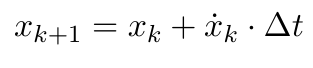

We used dt = 1 (delta t), for simplicity. You can do the same here. However, this time we also have the acceleration and therefore we use:

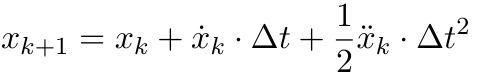

Finally, for a part of the video, the ball is behind something and can't be seen. Obviously we cant update our state here, because there is no measurement. So when there is no measurements available, you should only use the predict function and not the update function, to estimate the state.


# Challenge

If you can't get enough of tracking and Kalman filters, try extending your program, such that it can keep track of multiple balls at the same time. Use the video "rolling_ball_challenge.mp4" to test it. You can take advantage of the balls having different colours.